In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

from src.datos import obtener_serie_ipc
from src.modelos import seleccionar_especificacion_arima

In [2]:
#Datos
df = obtener_serie_ipc()
df['inflacion_mensual'] =(
    (  df['ipc_2016_nivel_general']/
       (df['ipc_2016_nivel_general']).shift(1)
    ) 
    - 1
    )
#Elimino los valores nulos, eliminando la primera columna
df = df.iloc[1:,]
df["log_ipc"] = np.log(df["ipc_2016_nivel_general"])

df.head()

,ipc_2016_nivel_general,inflacion_mensual,log_ipc
indice_tiempo,,,
2017-02-01,103.8085,0.024632,4.642548
2017-03-01,106.2627,0.023642,4.665914
2017-04-01,109.0613,0.026337,4.691910
2017-05-01,110.4607,0.012831,4.704660
2017-06-01,111.9943,0.013884,4.718448


In [3]:
#Selecciono los modelos
#Correr la búsqueda de la grilla
resultados_itera = seleccionar_especificacion_arima(df['log_ipc'])
resultados_itera.head()

,orden,p,d,q,BIC,AIC,convergencia,model_fit
0,"ARIMA(3,1,3)",3,1,3,-497.210584,-515.305356,False,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
1,"ARIMA(3,1,2)",3,1,2,-496.839202,-512.349006,False,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
2,"ARIMA(3,1,0)",3,1,0,-496.393106,-506.732976,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
3,"ARIMA(1,1,0)",1,1,0,-495.896601,-501.066536,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...
4,"ARIMA(1,1,2)",1,1,2,-494.498967,-504.838837,True,<statsmodels.tsa.arima.model.ARIMAResultsWrapp...


#### Pronostico

In [4]:
df['log_ipc'].count() #tenemos 99 datos
#Haremos una separacion train-test: 85-15 aprox
#train=85 y test=14
#(en este ejemplo se usan los últimos 14 registros para test)
#df['log_ipc'].index = pd.DatetimeIndex(df['log_ipc'].index).to_period('Q') #Convertir a PeriodIndex trimestral
train = df['log_ipc'].iloc[:-14]
test = df['log_ipc'].iloc[-14:]


##### Primer Modelo - ARIMA(3,1,0)

In [7]:
# 1. Ajustar el modelo ARIMA(3,1,0) con los datos de entrenamiento
modelo_1 = ARIMA(train, order=(3, 1, 0), trend='t').fit()
print("============ ARIMA (3,1,0) ================")
print(modelo_1.summary())
print("===========================================")

# 2. Realizar el pronóstico para el número de periodos del conjunto test
resultado_pronostico_1 = modelo_1.get_forecast(steps=len(test))
pronostico_modelo_1 = resultado_pronostico_1.predicted_mean

# 3. Calcular métricas de error (por ejemplo, MSE y RMSE)
mse_1 = mean_squared_error(test, pronostico_modelo_1)
rmse_1 = np.sqrt(mse_1)

#dice ="Maximum Likelihood optimization failed to converge"

============ ARIMA (3,1,0) ================
                               SARIMAX Results                                
Dep. Variable:                log_ipc   No. Observations:                   85
Model:                 ARIMA(3, 1, 0)   Log Likelihood                 228.128
Date:                Sat, 19 Sep 2026   AIC                           -446.257
Time:                        11:58:11   BIC                           -434.103
Sample:                    02-01-2017   HQIC                          -441.371
                         - 02-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0810      0.067      1.205      0.228      -0.051       0.213
ar.L1          0.8384      0.119      7.023      0.000       0.604       1.072
ar.L2   

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregres

##### Segundo Modelo - ARIMA(1,1,0)

In [8]:
# 1. Ajustar el modelo ARIMA(1,1,0) con los datos de entrenamiento
modelo_2 = ARIMA(train, order=(1, 1, 0), trend='t').fit()
print("============ ARIMA (1,1,0) ================")
print(modelo_2.summary())
print("===========================================")

# 2. Realizar el pronóstico para el número de periodos del conjunto test
resultado_pronostico_2 = modelo_2.get_forecast(steps=len(test))
pronostico_modelo_2 = resultado_pronostico_2.predicted_mean

# 3. Calcular métricas de error (por ejemplo, MSE y RMSE)
mse_2 = mean_squared_error(test, pronostico_modelo_2)
rmse_2 = np.sqrt(mse_2)

============ ARIMA (1,1,0) ================
                               SARIMAX Results                                
Dep. Variable:                log_ipc   No. Observations:                   85
Model:                 ARIMA(1, 1, 0)   Log Likelihood                 216.163
Date:                Sat, 19 Sep 2026   AIC                           -426.327
Time:                        11:58:17   BIC                           -419.034
Sample:                    02-01-2017   HQIC                          -423.395
                         - 02-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0509      0.023      2.191      0.028       0.005       0.096
ar.L1          0.8815      0.054     16.347      0.000       0.776       0.987
sigma2  

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


#### Comparacion de modelos

In [9]:
#Tabla comparativa de métricas fuera de muestra(out-of-sample)
df_resultado_de_modelos = pd.DataFrame({
    'Modelo': ['ARIMA(3,1,0)', 'ARIMA(1,1,0)'],
    'AIC (Train)': [modelo_1.aic, modelo_2.aic],
    'BIC (Train)': [modelo_2.bic, modelo_2.bic],
    'RMSE (Test)': [rmse_1, rmse_2],
    'Convergencia': ['Falló', 'Exitosa'],
    'Tendencia p-valor': [0.228, 0.028]
})
print(df_resultado_de_modelos.to_string())

         Modelo  AIC (Train)  BIC (Train)  RMSE (Test) Convergencia  Tendencia p-valor
0  ARIMA(3,1,0)  -446.256965  -419.034245     1.008679        Falló              0.228
1  ARIMA(1,1,0)  -426.326695  -419.034245     0.418809      Exitosa              0.028


Para la selección final del modelo se evaluó el desempeño tanto dentro de la muestra (mediante criterios de información AIC y BIC) como fuera de la muestra (evaluando el RMSE en un conjunto de prueba del 15% equivalente a 14 observaciones).Si bien el modelo ARIMA(3,1,0) mostro un AIC menor en entrenamiento, presentó una falla de convergencia en la estimación por máxima verosimilitud y a su vez su intercepto no fue significativo ($p = 0.228$). Asimismo, al evaluar la capacidad predictiva en el conjunto test, el modelo ARIMA(1,1,0) demostró superioridad, reduciendo el RMSE fuera de muestra de $1.0087$ a $0.4188$ (una mejora del $58.5\%$).Por su convergencia exitosa, significatividad de todos sus parámetros ($p < 0.05$), parsimonia y precisión predictiva fuera de muestra, se selecciona el modelo ARIMA(1,1,0) con drift como la especificación óptima para la proyección del IPC

#### Graficos

##### Grafico inflacion

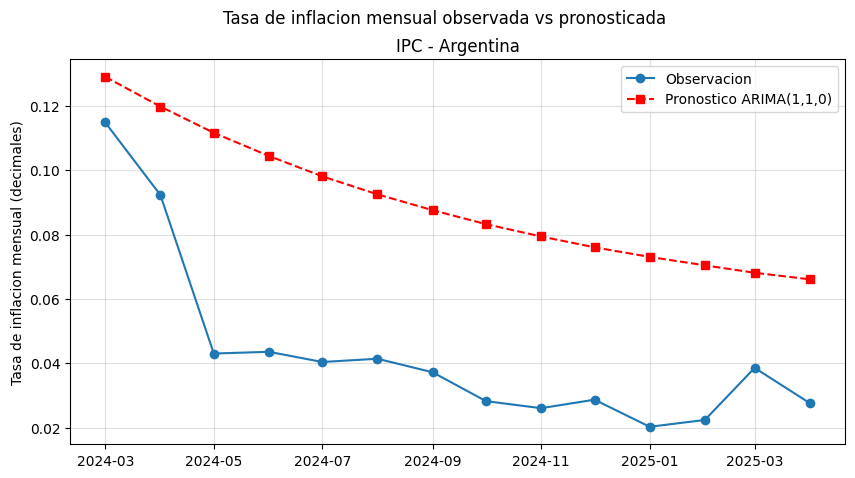

In [19]:
# Grafico los valores reales vs. pronosticados

# Mis valores pronosticados estan en terminos de ln(IPC) asi como el test
# Si quiero la tasa de inflacion, deberia tomar la primera diferencia de mis
#pronosticos y la serie observada de inflacion mensual ya la tengo

# Unir el último punto conocido con el pronóstico para calcular la primera diferencia
log_ipc_para_diff = pd.concat([train.iloc[-1:], pronostico_modelo_2])
inflacion_pronosticada = log_ipc_para_diff.diff().dropna()


plt.figure(figsize=(10, 5))
plt.plot(df.index[-len(test):], df['inflacion_mensual'].iloc[-len(test):,], label='Observacion', marker='o', linestyle='-')
plt.plot(inflacion_pronosticada.index , inflacion_pronosticada , label='Pronostico ARIMA(1,1,0)', marker='s', linestyle='--', color='red')
plt.ylabel('Tasa de inflacion mensual (decimales)')
plt.suptitle('Tasa de inflacion mensual observada vs pronosticada')
plt.title("IPC - Argentina")
plt.legend()
plt.grid(alpha=0.4)

##### Grafico del nivel del ipc

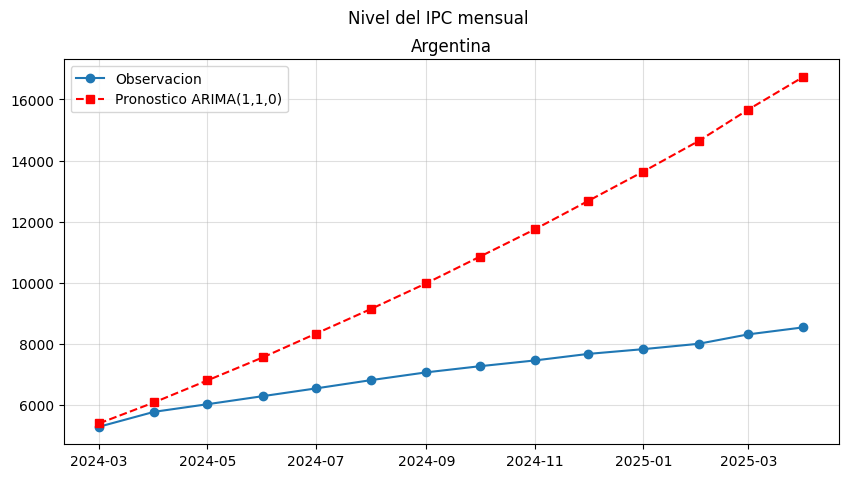

In [18]:
# Si quiero comparar el nivel del IPC debo tomar la exponencial de mis pronosticos, dado 
#que se encuentran en ln(IPC) y luego la serie del nivel general mensual ya lo tengo
ipc_pronosticado = np.exp(pronostico_modelo_2)

plt.figure(figsize=(10, 5))
plt.suptitle("Nivel del IPC mensual")
plt.title("Argentina")
plt.plot(df['ipc_2016_nivel_general'].index[-len(test):], 
         df['ipc_2016_nivel_general'].iloc[-len(test):],
         label='Observacion', marker='o', linestyle='-')
plt.plot(ipc_pronosticado.index, ipc_pronosticado, label='Pronostico ARIMA(1,1,0)',
         marker='s', linestyle='--', color='red')
plt.legend()
plt.grid(alpha=0.4)


Desempeño Fuera de Muestra (Out-of-Sample)Sesgo de Sobreestimación: El modelo ARIMA(1,1,0) sobreestimó sistemáticamente la inflación mensual durante 2024–2025. Esto ocurre porque los coeficientes autoregresivos ($\phi_1 \approx 0.88$) capturaron la inercia inflacionaria del período de entrenamiento (alta inflación), resultando rígidos ante el proceso de desaceleración.\
Efecto Compuesto en Niveles: Mientras que la discrepancia mensual en la tasa oscila entre $2$ y $5$ puntos porcentuales, el impacto acumulado sobre el Nivel del IPC escala exponencialmente.

#### Intervalos de prediccion

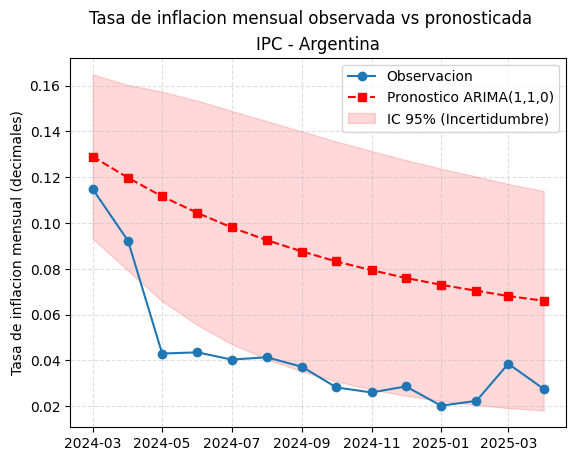

In [20]:
#Intervalo de confianza al 95% del modelo
intervalo_conf_log = resultado_pronostico_2.conf_int(alpha=0.05)

# Unimos el último punto de train con el pronóstico central y sus límites
log_ipc_para_diff = pd.concat([train.iloc[-1:], pronostico_modelo_2])
IC_inf_ipc_para_diff = pd.concat([train.iloc[-1:], intervalo_conf_log.iloc[:, 0]])
IC_sup_ipc_para_diff = pd.concat([train.iloc[-1:], intervalo_conf_log.iloc[:, 1]])

# Calculamos las tasas de inflación (primeras diferencias)
inflacion_pronosticada = log_ipc_para_diff.diff().dropna()
IC_inf_inflacion = IC_inf_ipc_para_diff.diff().dropna()
IC_sup_inflacion = IC_sup_ipc_para_diff.diff().dropna()

#Grafico
plt.plot(df.index[-len(test):], df['inflacion_mensual'].iloc[-len(test):], 
         label='Observacion', marker='o', linestyle='-')
plt.plot(inflacion_pronosticada.index, inflacion_pronosticada, 
         label='Pronostico ARIMA(1,1,0)', marker='s', linestyle='--', color='red')

# Intervalo de confianza al 95%
plt.fill_between(inflacion_pronosticada.index, IC_inf_inflacion, IC_sup_inflacion,
                 color='red', alpha=0.15, label='IC 95% (Incertidumbre)')

plt.ylabel('Tasa de inflacion mensual (decimales)')
plt.suptitle('Tasa de inflacion mensual observada vs pronosticada')
plt.title("IPC - Argentina")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.4)

In [21]:
# Cobertura efectiva dentro de la banda al 95%
obs_test = df['inflacion_mensual'].iloc[-len(test):]
dentro_banda = (obs_test >= IC_inf_inflacion) & (obs_test <= IC_sup_inflacion)
porcentaje_cobertura = dentro_banda.mean() * 100

print(f"Porcentaje de cobertura del IC 95%: {np.round(porcentaje_cobertura,2)}%")

Porcentaje de cobertura del IC 95%: 57.14%


Evaluación de la Cobertura Empírica del Intervalo de Confianza (Backtesting):Las observaciones solo tuvieron una cobertura real del 57.14%. Esta pérdida significativa en la cobertura del intervalo (sustancialmente por debajo del 95% teórico) confirma empíricamente la presencia de un quiebre en la dinámica inflacionaria. La acelerada convergencia hacia la baja superó la cola inferior del abanico probabilístico previsto por la estructura ARIMA. Lo que muestra el riesgo de subestimar el ritmo de desinflación durante procesos de estabilización si se depende de estimadores exclusivamente históricos